# Parity Experiment Analysis (Z / X / Y)

Canonical analysis for the combined `ParityExperiment` HDF5 output (also reads
legacy `ZParityExperiment` files). Replaces `analyze_z_parity.ipynb`.

The **basis is auto-detected** per file from `datasets.attrs['basis_axis']`
(Z / X / Y); legacy single-basis files fall back to the filename, then to Z.
"Latest run" = the **highest RID**. Colors, labels, and titles follow the
detected basis. Methodology from `archive/Analysis/parity_lib.py` + `registry.py`.

**Parity model:** `C*(1 + V*cos(deg2rad(4*HWP - phase)))`, fixed f=4.

**Bases:** single-basis parity per run (Z, X, or Y). Full Bell fidelity needs
Z+X+Y; see the multi-basis cell (set `FILE_X`/`FILE_Y` to the X/Y run paths).

## 0. Setup

In [1516]:
import sys
import os
import json
import glob
import datetime
from pathlib import Path

import numpy as np
import pandas as pd
import h5py
import matplotlib.pyplot as plt
import matplotlib as mpl
from scipy.optimize import least_squares

# --- Add archive/Analysis to sys.path so parity_lib and registry import cleanly ---
ARCHIVE_ANALYSIS = str(
    Path(r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\archive\Analysis")
)
if ARCHIVE_ANALYSIS not in sys.path:
    sys.path.insert(0, ARCHIVE_ANALYSIS)

from parity_lib import (
    cos4_physical,
    get_fit_point_error,
    select_theta_opt,
    select_big_small,
    extract_quadratures_fit,
    extract_quadratures_exp,
    plot_parity_panel,
    plot_bar_panel,
    apply_pub_style,
    COLORS_PARITY,
    COLORS_BAR,
    fidelity_two_basis,
    fidelity_three_basis,
    correlator_per_basis,
    create_figure,
)
from registry import qwp_max_fid_estimate

apply_pub_style()
%matplotlib inline
%config InlineBackend.figure_format = 'svg'

RESULTS_DIR = Path(
    r"C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results"
)
print(f"Results dir: {RESULTS_DIR}")
print(f"parity_lib loaded from: {ARCHIVE_ANALYSIS}")
print("Setup complete.")

Results dir: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results
parity_lib loaded from: C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\archive\Analysis
Setup complete.


## 1. Helpers: `load_h5_as_df`, `safe_fit_cos4`, `safe_analyze_qwp_slice`

**`load_h5_as_df`** maps the `.h5` datasets to the DataFrame columns expected by
`parity_lib.analyze_qwp_slice`:

| parity_lib column | .h5 dataset          | Notes |
|-------------------|----------------------|-------|
| `SPCM1`           | `SPCM1_timestamps`   | float64; 0.0=no click, >0=click time in s |
| `SPCM2`           | `SPCM2_timestamps`   | same |
| `trials`          | `trials_per_meas`    | int; excitation trials per heralded meas |
| `counts`          | `counts_signal`      | int; final-readout fluorescence, raw |
| `counts_bg`       | `counts_background`  | available if operator wants to subtract |
| `HWP`             | `HWP_angles`         | float deg |
| `QWP`             | `QWP_angles`         | float deg |

**Sentinel note:** archive CSVs use `-2` for no-click; `.h5` uses `0.0`.
`analyze_qwp_slice` checks `frac_m2 = mean(SPCM==-2)` and falls back to
`det=(SPCM>0)` when `frac_m2 < 0.01` — which is always the case for `.h5` data.
Do NOT convert `0.0 -> -2`.

**Threshold:** parity_lib uses raw `counts >= hist_thres` (no background subtraction),
matching the archive convention. `counts_bg` is available in the df if the operator
wants to subtract it, but is not used by default.

**`safe_fit_cos4`** is a platform-safe replacement for `parity_lib.fit_cos4`.
`scipy.optimize.curve_fit` with tight frequency bounds (`|df|=1e-7`) hangs
indefinitely on `scipy 1.11.4 / numpy 1.23.5 / cblas` on this Windows machine.
`np.dot`/`@` and `np.linalg.inv` also segfault via the broken cblas library.
This replacement uses `least_squares(method='lm')`, `np.einsum` for J^T J, and
Cramer's rule for the 3x3 covariance inversion. Returns `(popt, info)` in
identical format to `parity_lib.fit_cos4`.

**`safe_analyze_qwp_slice`** is identical in logic to `parity_lib.analyze_qwp_slice`
but substitutes `safe_fit_cos4` for `parity_lib.fit_cos4`.

In [1517]:
def load_h5_as_df(h5_path):
    """
    Load a ZParityExperiment HDF5 file into a DataFrame using the parity_lib
    column convention (SPCM1, SPCM2, trials, counts, counts_bg, HWP, QWP).

    Also returns atom_threshold from archive/atom_threshold (default 12.0).
    """
    with h5py.File(h5_path, "r", locking=False) as hf:
        def _ds(key):
            return hf[f"datasets/{key}"][()]
        spcm1     = _ds("SPCM1_timestamps").astype(float)
        spcm2     = _ds("SPCM2_timestamps").astype(float)
        trials    = _ds("trials_per_meas").astype(int)
        counts    = _ds("counts_signal").astype(int)
        counts_bg = _ds("counts_background").astype(int)
        hwp       = _ds("HWP_angles").astype(float)
        qwp       = _ds("QWP_angles").astype(float)
        if "archive/atom_threshold" in hf:
            atom_threshold = float(hf["archive/atom_threshold"][()])
        else:
            atom_threshold = 12.0
    df = pd.DataFrame({
        "SPCM1":     spcm1,
        "SPCM2":     spcm2,
        "trials":    trials,
        "counts":    counts,
        "counts_bg": counts_bg,
        "HWP":       hwp,
        "QWP":       qwp,
    })
    return df, atom_threshold


def _inv3x3(M):
    """Manual 3x3 matrix inverse via Cramer's rule (avoids LAPACK/BLAS crash)."""
    a, b, c = float(M[0,0]), float(M[0,1]), float(M[0,2])
    d, e, f = float(M[1,0]), float(M[1,1]), float(M[1,2])
    g, h, k = float(M[2,0]), float(M[2,1]), float(M[2,2])
    det = a*(e*k - f*h) - b*(d*k - f*g) + c*(d*h - e*g)
    if abs(det) < 1e-15:
        return np.eye(3) * 1e6
    inv = np.empty((3, 3), dtype=float)
    inv[0,0] =  (e*k - f*h) / det;  inv[0,1] = -(b*k - c*h) / det;  inv[0,2] =  (b*f - c*e) / det
    inv[1,0] = -(d*k - f*g) / det;  inv[1,1] =  (a*k - c*g) / det;  inv[1,2] = -(a*f - c*d) / det
    inv[2,0] =  (d*h - e*g) / det;  inv[2,1] = -(a*h - b*g) / det;  inv[2,2] =  (a*e - b*d) / det
    return inv


def safe_fit_cos4(x, y, yerr, fixed_freq=4.0):
    """
    Platform-safe replacement for parity_lib.fit_cos4.

    scipy.optimize.curve_fit with tight frequency bounds hangs indefinitely on
    scipy 1.11.4 / numpy 1.23.5 / cblas on this Windows platform.  np.dot/@
    and np.linalg.inv also crash via the broken cblas library.

    This implementation:
      - Uses least_squares(method='lm') — no tight bounds, no cblas call.
      - Computes J^T J via np.einsum (pure numpy dispatch, no BLAS).
      - Inverts the 3x3 covariance via Cramer's rule (no LAPACK).

    Returns (popt, info) in identical format to parity_lib.fit_cos4:
      popt = [C, V, phase_deg, fixed_freq]
      info = {'vis', 'vis_err', 'popt', 'pcov' (4x4), 'y_smooth'}
    """
    C0 = max(float(np.mean(y)), 1e-9)
    amp_est = (float(np.max(y)) - float(np.min(y))) / 2.0
    V0 = float(np.clip(amp_est / C0, 0.05, 0.95))

    # Grid-search starting phase (matches parity_lib.fit_cos4 logic)
    best_p0 = [C0, V0, 0.0]
    best_cost = np.inf
    for ph in range(0, 360, 45):
        y_mod = cos4_physical(x, C0, V0, float(ph), fixed_freq)
        cost = float(np.sum(((y_mod - y) / np.maximum(yerr, 1e-9)) ** 2))
        if cost < best_cost:
            best_cost = cost
            best_p0 = [C0, V0, float(ph)]

    def residuals(p):
        C_r, V_r, phi = p
        return (
            cos4_physical(x, max(float(C_r), 1e-9),
                          float(np.clip(V_r, 0.0, 1.0)),
                          float(phi), fixed_freq) - y
        ) / np.maximum(yerr, 1e-9)

    try:
        result = least_squares(residuals, best_p0, method='lm', max_nfev=5000,
                               ftol=1e-10, xtol=1e-10, gtol=1e-10)
        C_f   = max(float(result.x[0]), 0.0)
        V_f   = float(np.clip(result.x[1], 0.0, 1.0))
        phi_f = float(result.x[2])
        popt  = np.array([C_f, V_f, phi_f, fixed_freq])

        J     = np.asarray(result.jac, dtype=float)   # (n_data, 3)
        n_d, n_p = J.shape
        chi2  = float(np.sum(result.fun ** 2))
        dof   = max(n_d - n_p, 1)
        JtJ   = np.einsum('ki,kj->ij', J, J)           # (3,3); no BLAS call
        pcov_3 = _inv3x3(JtJ) * (chi2 / dof)

        # Expand to 4x4 (4th param = f, fixed; its row/col = 0)
        pcov = np.zeros((4, 4), dtype=float)
        pcov[:3, :3] = pcov_3

        V_err    = float(np.sqrt(max(0.0, pcov[1, 1])))
        theta_sm = np.linspace(float(x.min()), float(x.max()), 500)
        y_smooth = cos4_physical(theta_sm, C_f, V_f, phi_f, fixed_freq)
        return popt, {
            'vis': V_f, 'vis_err': V_err,
            'popt': popt, 'pcov': pcov, 'y_smooth': y_smooth,
        }

    except Exception:
        # Fallback: return grid-search best with zero covariance
        C0_  = max(float(best_p0[0]), 0.0)
        V0_  = float(np.clip(best_p0[1], 0.0, 1.0))
        phi0 = float(best_p0[2])
        popt_fb = np.array([C0_, V0_, phi0, fixed_freq])
        theta_sm = np.linspace(float(x.min()), float(x.max()), 500)
        return popt_fb, {
            'vis': 0.0, 'vis_err': 0.0,
            'popt': popt_fb, 'pcov': np.zeros((4, 4)),
            'y_smooth': cos4_physical(theta_sm, C0_, V0_, phi0, fixed_freq),
        }


def safe_analyze_qwp_slice(d, hist_thres=18):
    """
    Identical logic to parity_lib.analyze_qwp_slice but uses safe_fit_cos4
    instead of parity_lib.fit_cos4 (platform-safe for this scipy/numpy version).

    Takes a DataFrame slice for a single QWP value with columns:
      SPCM1, SPCM2, counts, HWP, QWP

    Returns {'angles', 'theta_smooth', 'res', 'fits'} or None if <4 HWP angles.
    res keys: p_S0_L, p_S1_L, p_S0_E, p_S1_E (+ e_ errors), parity_plus, parity_minus.
    fits keys: same 6 target keys, each an info dict from safe_fit_cos4.
    """
    if len(d) == 0:
        return None

    frac_m2 = float(np.mean((d['SPCM1'] == -2) | (d['SPCM2'] == -2)))
    det0 = (d['SPCM1'] != -2) if frac_m2 > 0.01 else (d['SPCM1'] > 0)
    det1 = (d['SPCM2'] != -2) if frac_m2 > 0.01 else (d['SPCM2'] > 0)
    atom = (d['counts'] >= hist_thres)

    single_click = np.logical_xor(det0, det1)
    valid_mask = (
        single_click.values
        & np.isfinite(d['HWP'].values)
        & np.isfinite(d['counts'].values)
    )

    d_valid = d[valid_mask]
    det0v   = det0.values[valid_mask]
    det1v   = det1.values[valid_mask]
    atomv   = atom.values[valid_mask]
    hwp     = d_valid['HWP'].values

    angles = np.sort(np.unique(hwp))
    if len(angles) < 4:
        return None

    keys = [
        'p_S0_L', 'p_S1_L', 'p_S0_E', 'p_S1_E',
        'e_S0_L', 'e_S1_L', 'e_S0_E', 'e_S1_E',
        'parity_plus', 'parity_minus', 'e_parity_plus', 'e_parity_minus',
    ]
    res = {k: [] for k in keys}

    for ang in angles:
        mask = (hwp == ang)
        N = int(np.sum(mask))
        if N == 0:
            continue
        d0a = det0v[mask]; d1a = det1v[mask]; aa = atomv[mask]
        k_S0_L = int(np.sum(d0a & (~aa)))
        k_S1_L = int(np.sum(d1a & (~aa)))
        k_S0_E = int(np.sum(d0a & aa))
        k_S1_E = int(np.sum(d1a & aa))

        def _pe(k, n):
            p = k / n
            e = np.sqrt(p * (1 - p) / n) if n > 0 else 0.0
            return p, max(e, 1e-4)

        p_S0_L, e_S0_L = _pe(k_S0_L, N)
        p_S1_L, e_S1_L = _pe(k_S1_L, N)
        p_S0_E, e_S0_E = _pe(k_S0_E, N)
        p_S1_E, e_S1_E = _pe(k_S1_E, N)

        res['p_S0_L'].append(p_S0_L); res['e_S0_L'].append(e_S0_L)
        res['p_S1_L'].append(p_S1_L); res['e_S1_L'].append(e_S1_L)
        res['p_S0_E'].append(p_S0_E); res['e_S0_E'].append(e_S0_E)
        res['p_S1_E'].append(p_S1_E); res['e_S1_E'].append(e_S1_E)

        res['parity_plus'].append(p_S0_L + p_S1_E)
        res['parity_minus'].append(p_S1_L + p_S0_E)
        res['e_parity_plus'].append(np.sqrt(e_S0_L ** 2 + e_S1_E ** 2))
        res['e_parity_minus'].append(np.sqrt(e_S1_L ** 2 + e_S0_E ** 2))

    for k in res:
        res[k] = np.array(res[k])

    fits = {}
    target_keys = ['p_S0_L', 'p_S1_L', 'p_S0_E', 'p_S1_E', 'parity_plus', 'parity_minus']
    err_keys    = ['e_S0_L', 'e_S1_L', 'e_S0_E', 'e_S1_E', 'e_parity_plus', 'e_parity_minus']
    theta_smooth = np.linspace(float(min(angles)), float(max(angles)), 500)
    for k, ek in zip(target_keys, err_keys):
        _, info = safe_fit_cos4(angles, res[k], res[ek], fixed_freq=4.0)
        fits[k] = info

    return {'angles': angles, 'theta_smooth': theta_smooth, 'res': res, 'fits': fits}


print("Helpers defined: load_h5_as_df, safe_fit_cos4, safe_analyze_qwp_slice")

Helpers defined: load_h5_as_df, safe_fit_cos4, safe_analyze_qwp_slice


In [1518]:
def read_basis(h5_path):
    """Return the parity basis ('Z' / 'X' / 'Y') for a parity .h5 file.

    The combined ParityExperiment records the basis as a string attribute on the
    datasets group: datasets.attrs['basis_axis']. Legacy single-basis files
    (e.g. ZParityExperiment) have no such attr, so fall back to the filename,
    then default to 'Z'.
    """
    try:
        with h5py.File(h5_path, "r", locking=False) as hf:
            if "datasets" in hf and "basis_axis" in hf["datasets"].attrs:
                b = hf["datasets"].attrs["basis_axis"]
                b = b.decode() if isinstance(b, bytes) else str(b)
                if b in ("Z", "X", "Y"):
                    return b
    except Exception:
        pass
    name = os.path.basename(h5_path).upper()
    if "ZPARITY" in name:
        return "Z"
    if "XPARITY" in name:
        return "X"
    if "YPARITY" in name:
        return "Y"
    return "Z"


print("Helper defined: read_basis (auto-detects Z/X/Y from datasets.attrs['basis_axis'])")

Helper defined: read_basis (auto-detects Z/X/Y from datasets.attrs['basis_axis'])


## 2. List Available ZParityExperiment Runs

In [1519]:
def _rid_of(path):
    try:
        return int(os.path.basename(path).split("-")[0])
    except Exception:
        return -1

parity_files = sorted(
    glob.glob(str(RESULTS_DIR / "**" / "*ParityExperiment.h5"), recursive=True),
    key=_rid_of,
)

if not parity_files:
    print(f"No (Z/X/Y)ParityExperiment HDF5 files found under {RESULTS_DIR}")
else:
    print(f"{'RID':>9s}  {'Basis':>5s}  {'Date':<12s}  {'HH':>4s}  {'N_rows':>7s}  "
          f"{'QWP_pts':>7s}  {'HWP_pts':>7s}  Path")
    print("-" * 88)
    for fpath in parity_files:
        rid_str = str(_rid_of(fpath))
        mtime = datetime.datetime.fromtimestamp(os.path.getmtime(fpath))
        n_rows = qwp_pts = hwp_pts = "?"
        try:
            with h5py.File(fpath, "r", locking=False) as hf:
                if "datasets/HWP_angles" in hf:
                    hwp_arr = hf["datasets/HWP_angles"][()]
                    qwp_arr = hf["datasets/QWP_angles"][()]
                    n_rows  = str(len(hwp_arr))
                    qwp_pts = str(len(np.unique(qwp_arr)))
                    hwp_pts = str(len(np.unique(hwp_arr)))
        except Exception:
            pass
        basis = read_basis(fpath)
        rel = str(Path(fpath).relative_to(RESULTS_DIR).parent)
        date_str = mtime.strftime("%Y-%m-%d")
        hh_str   = mtime.strftime("%H")
        print(f"{rid_str:>9s}  {basis:>5s}  {date_str:<12s}  {hh_str:>4s}  "
              f"{n_rows:>7s}  {qwp_pts:>7s}  {hwp_pts:>7s}  {rel}")

      RID  Basis  Date            HH   N_rows  QWP_pts  HWP_pts  Path
----------------------------------------------------------------------------------------
      508      Z  2026-06-09      09     1902        3        9  2026-06-08\23
      561      Z  2026-06-10      15     9000       10        9  2026-06-10\09
      564      X  2026-06-10      17     4461        5        9  2026-06-10\15
      568      X  2026-06-10      23     7943        9        9  2026-06-10\18
      571      X  2026-06-11      05     9000       10        9  2026-06-10\23
      600      Z  2026-06-11      22     8100        9        9  2026-06-11\18
      630      Z  2026-06-12      13     4500        5        9  2026-06-12\11
      650      Z  2026-06-12      15      317        1        4  2026-06-12\15
      653      Z  2026-06-12      16      431        1        5  2026-06-12\15
      656      Z  2026-06-12      17     5000        5       10  2026-06-12\16
      731      X  2026-06-23      18     7000      

      744      X  2026-06-30      12     5000        5       10  2026-06-30\10
      751      Z  2026-07-01      13     3111        5        7  2026-07-01\11
      759      Z  2026-07-02      18     2400        4        7  2026-07-02\17
      768      X  2026-07-02      22     7000       10        7  2026-07-02\19
      778      X  2026-07-07      12     7000       10        7  2026-07-07\09
      781      X  2026-07-07      16     7000       10        7  2026-07-07\13
      921      X  2026-07-08      00       27        1        1  2026-07-08\00
      924      X  2026-07-08      08    20286       29        7  2026-07-08\00
      927      X  2026-07-08      09     4268        7        7  2026-07-08\08
     1000      X  2026-07-08      15     7000       10        7  2026-07-08\13
     1003      X  2026-07-08      20     7000       10        7  2026-07-08\17
     1009      Y  2026-07-09      02     7000       10        7  2026-07-08\23
     1021      Y  2026-07-10      03     7000       

## 3. Select and Load Run

Set `RID` to an integer run ID, or `None` to auto-select the latest ZParityExperiment file.

In [ ]:
########################################
RID = None   # <-- set to int (e.g. 561) or None for the latest (highest RID)
########################################

def _rid_of(path):
    try:
        return int(os.path.basename(path).split("-")[0])
    except Exception:
        return -1

parity_files = sorted(
    glob.glob(str(RESULTS_DIR / "**" / "*ParityExperiment.h5"), recursive=True),
    key=_rid_of,
)
if not parity_files:
    raise FileNotFoundError(f"No (Z/X/Y)ParityExperiment .h5 under {RESULTS_DIR}")

if RID is not None:
    cand = [f for f in parity_files if _rid_of(f) == int(RID)]
    if not cand:
        raise FileNotFoundError(f"No ParityExperiment .h5 for RID {RID}")
    filepath = max(cand, key=os.path.getmtime)
else:
    # 'latest' = highest RID (robust to the results date/hour directory layout)
    filepath = max(parity_files, key=_rid_of)
    print(f"(Using latest ParityExperiment run: RID {_rid_of(filepath)})")

print(f"File : {os.path.basename(filepath)}")
print(f"Path : {filepath}")

# Auto-detect the parity basis (Z/X/Y) for this file
basis = read_basis(filepath)

# Load into DataFrame
df, _atom_threshold_file = load_h5_as_df(filepath)

run_rid = _rid_of(filepath)
unique_qwp = np.sort(df["QWP"].unique())
unique_hwp = np.sort(df["HWP"].unique())

# Read run metadata from metadata.attrs (where write_results stores it), plus
# how_many_atoms = atom load attempts per heralded measurement (parity.py).
_meta = {}
_hma = np.array([])
with h5py.File(filepath, "r", locking=False) as hf:
    if "metadata" in hf:
        for k, v in hf["metadata"].attrs.items():
            _meta[k] = v.decode() if isinstance(v, bytes) else v
    if "datasets/how_many_atoms" in hf:
        _hma = np.asarray(hf["datasets/how_many_atoms"][()], dtype=float)

print(f"\nRID          : {run_rid}")
print(f"Loaded rows  : {len(df)}")
print(f"Basis        : {basis} (parity)")
print(f"atom_threshold (from file): {_atom_threshold_file}")
print(f"Unique QWP ({len(unique_qwp)}): {unique_qwp} deg")
print(f"Unique HWP ({len(unique_hwp)}): {unique_hwp} deg")

print(f"Success probability : {len(df) / df['trials'].sum() * 100:.2f} %")
if _hma.size > 0:
    print(f"Avg atom load attempts / measurement : {_hma.mean():.2f}  "
          f"(min {int(_hma.min())}, max {int(_hma.max())}, N={_hma.size})")
else:
    print("Avg atom load attempts / measurement : n/a (how_many_atoms not recorded in this run)")
if 'start_time' in _meta:
    print(f"start_time   : {_meta.get('start_time')}")
if 'end_time' in _meta:
    print(f"end_time     : {_meta.get('end_time')}")
if 'duration_seconds' in _meta:
    dur_s = float(_meta['duration_seconds'])
    print(f"duration     : {dur_s:.1f} s  ({dur_s/3600:.2f} h)")
    print(f"Photon click rate : {len(df) / dur_s:.2f} clicks/s")

File : 000002358-ParityExperiment.h5
Path : C:\Networking Experiment\Artiq7_TEST_NEW\useful_codes\repository\results\2026-09-11\01\000002358-ParityExperiment.h5

RID          : 2358
Loaded rows  : 7000
Basis        : Y (parity)
atom_threshold (from file): 14.0
Unique QWP (10): [ 10.  20.  30.  40.  50.  60.  70.  80.  90. 100.] deg
Unique HWP (7): [ 10.  25.  40.  55.  70.  85. 100.] deg
Success probability : 0.80 %
Avg atom load attempts / measurement : 2.38  (min 1, max 21, N=7000)
start_time   : 2026-09-11T01:19:22.088787
end_time     : 2026-09-11T04:21:20.854500
duration     : 10918.8 s  (3.03 h)
Photon click rate : 0.64 clicks/s


## 4. Threshold Tuning

Histogram of `counts_signal` (raw fluorescence) and `counts_background`.
Adjust `HIST_THRES` so the vertical line falls in the valley between the
dark (below) and bright (above) atom peaks.

`parity_lib` uses **raw `counts >= HIST_THRES`** (no background subtraction),
matching the archive analysis convention.

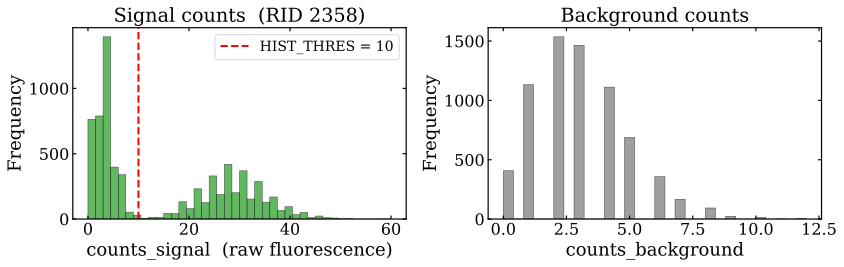

HIST_THRES = 10
counts_signal: min=0  max=60  mean=15.0
counts_background: min=0  max=12  mean=3.0
Atom-present fraction: 46.3%  (3238/7000)


In [1521]:
########################################
HIST_THRES = int(_atom_threshold_file)   # <-- edit from histogram valley; default = file value
########################################
HIST_THRES = 10

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.hist(df["counts"].values, bins=40, color="C2", alpha=0.75,
        edgecolor="black", lw=0.5)
ax.axvline(HIST_THRES, color="red", lw=2, ls="--",
           label=f"HIST_THRES = {HIST_THRES}")
ax.set_xlabel("counts_signal  (raw fluorescence)")
ax.set_ylabel("Frequency")
ax.set_title(f"Signal counts  (RID {run_rid})")
ax.legend()

ax = axes[1]
ax.hist(df["counts_bg"].values, bins=30, color="C7", alpha=0.75,
        edgecolor="black", lw=0.5)
ax.set_xlabel("counts_background")
ax.set_ylabel("Frequency")
ax.set_title("Background counts")

plt.tight_layout()
plt.show()

atom_present = (df["counts"].values >= HIST_THRES)
print(f"HIST_THRES = {HIST_THRES}")
print(f"counts_signal: min={df['counts'].min()}  max={df['counts'].max()}  "
      f"mean={df['counts'].mean():.1f}")
print(f"counts_background: min={df['counts_bg'].min()}  max={df['counts_bg'].max()}  "
      f"mean={df['counts_bg'].mean():.1f}")
print(f"Atom-present fraction: {atom_present.mean()*100:.1f}%  ({atom_present.sum()}/{len(df)})")

## 5. Per-QWP Analysis (core)

For each distinct QWP value:
1. Slice the DataFrame to that QWP.
2. Run `safe_analyze_qwp_slice` (= `parity_lib.analyze_qwp_slice` logic with
   platform-safe fitting) to get per-HWP populations and cos^4 fits.
3. Call `select_theta_opt` to find the HWP angle of maximum parity contrast.
4. Call `qwp_max_fid_estimate` (registry.py) for the per-QWP F_max estimate
   `0.5*(A+D+2*sqrt(A*D))` from the top-2 quadratures.
5. Render two panels: `plot_parity_panel` (left) + `plot_bar_panel` (right).
6. QWP slices with fewer than 4 HWP angles are skipped with an explanation.


QWP = 10.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.7237 +/- 0.0351
  vis_minus      = 0.7682 +/- 0.0278
  theta_opt      = 63.57 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.8720 +/- 0.0404


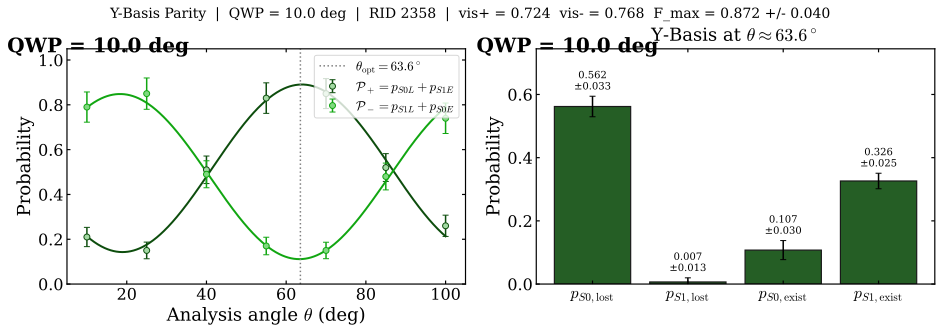


QWP = 20.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.6837 +/- 0.0542
  vis_minus      = 0.6675 +/- 0.0519
  theta_opt      = 25.15 deg  (plus_dominant = False)
  F_max (per-QWP estimator, registry.py) = 0.8157 +/- 0.0720


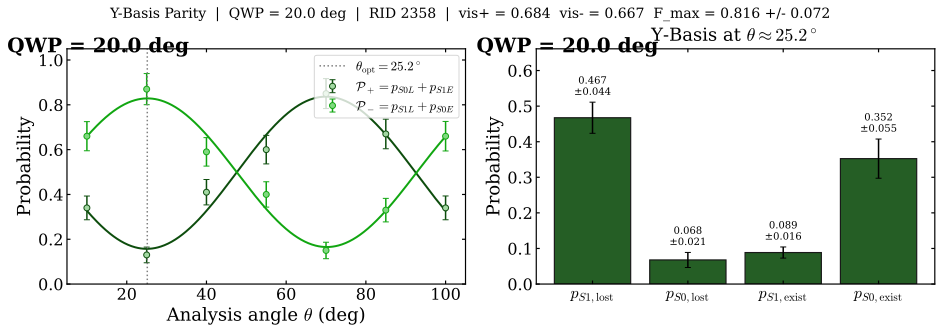


QWP = 30.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.6366 +/- 0.0378
  vis_minus      = 0.6907 +/- 0.0299
  theta_opt      = 77.82 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.8246 +/- 0.0604


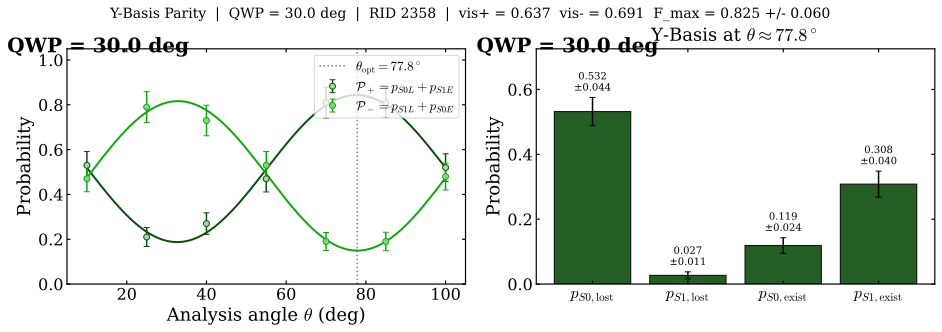


QWP = 40.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.5042 +/- 0.0527
  vis_minus      = 0.5415 +/- 0.0516
  theta_opt      = 85.03 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.7341 +/- 0.0514


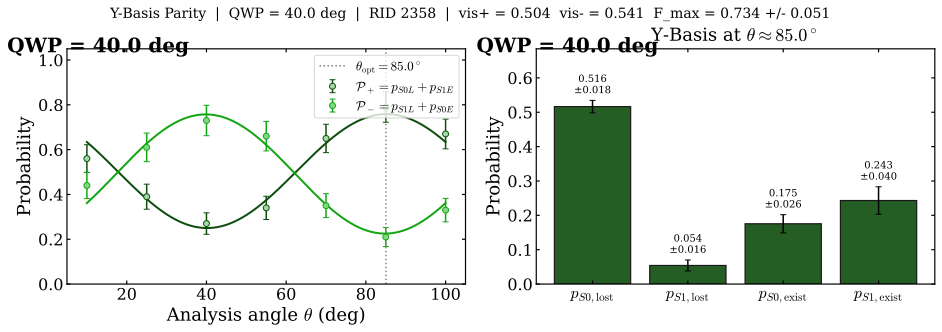


QWP = 50.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.5598 +/- 0.0736
  vis_minus      = 0.5464 +/- 0.0547
  theta_opt      = 50.94 deg  (plus_dominant = False)
  F_max (per-QWP estimator, registry.py) = 0.8000 +/- 0.0391


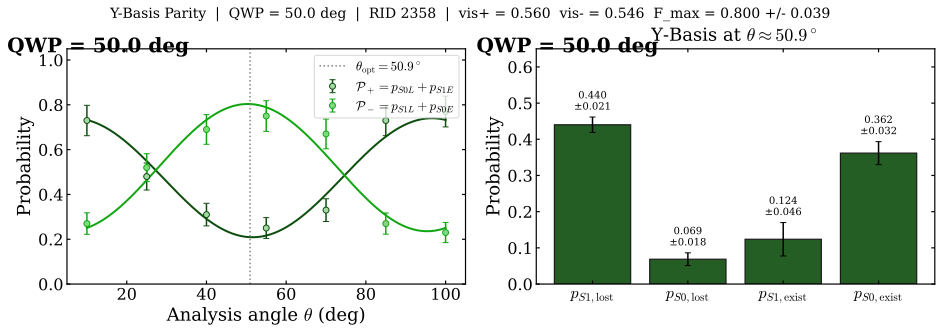


QWP = 60.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.5198 +/- 0.0489
  vis_minus      = 0.5978 +/- 0.0652
  theta_opt      = 15.23 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.8028 +/- 0.0375


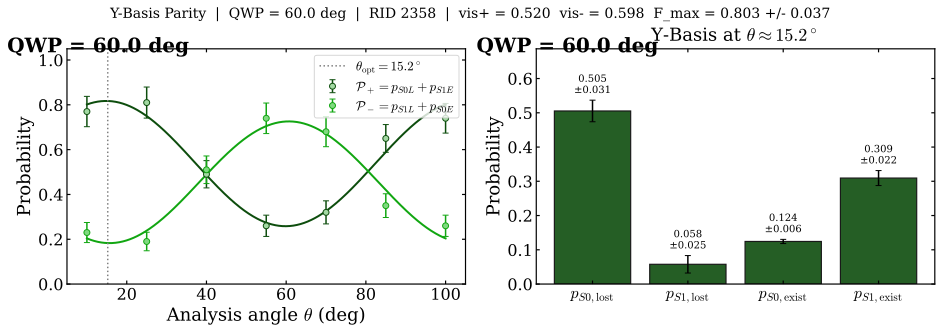


QWP = 70.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.6613 +/- 0.0440
  vis_minus      = 0.6848 +/- 0.0394
  theta_opt      = 22.44 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.8253 +/- 0.0642


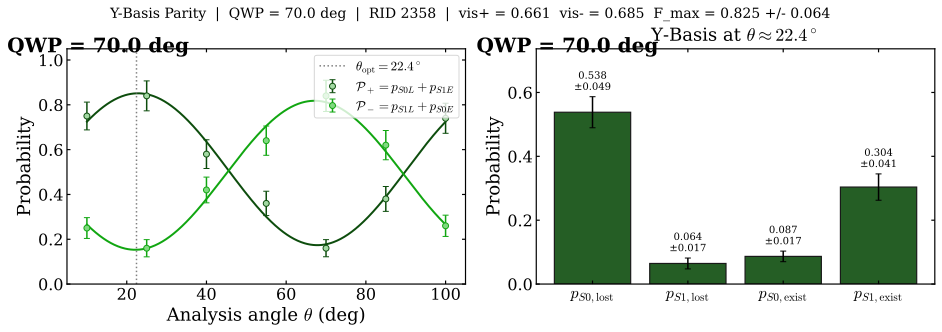


QWP = 80.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.7638 +/- 0.0620
  vis_minus      = 0.7817 +/- 0.0586
  theta_opt      = 30.56 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.8702 +/- 0.0470


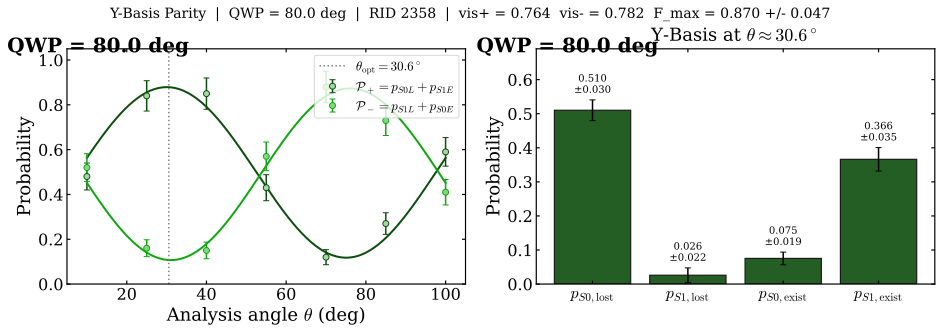


QWP = 90.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.7141 +/- 0.0663
  vis_minus      = 0.8326 +/- 0.0490
  theta_opt      = 34.89 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.8664 +/- 0.0550


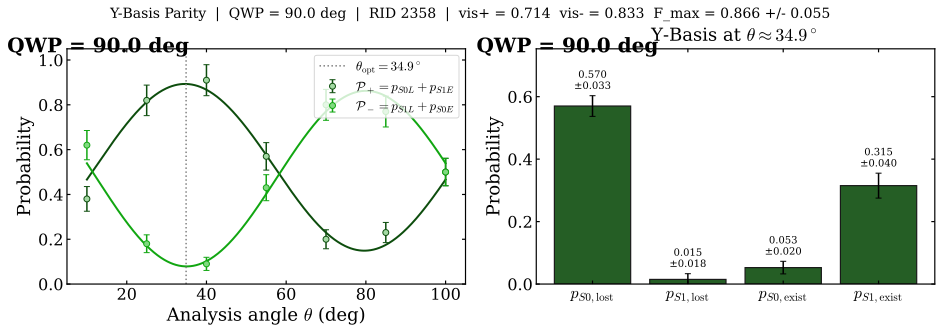


QWP = 100.0 deg  |  N = 700 rows  |  HWP angles in slice: 7
  n_angles_valid = 7  |  HWP range = 10.0 -- 100.0 deg
  vis_plus       = 0.6634 +/- 0.0401
  vis_minus      = 0.7071 +/- 0.0651
  theta_opt      = 40.48 deg  (plus_dominant = True)
  F_max (per-QWP estimator, registry.py) = 0.8624 +/- 0.0400


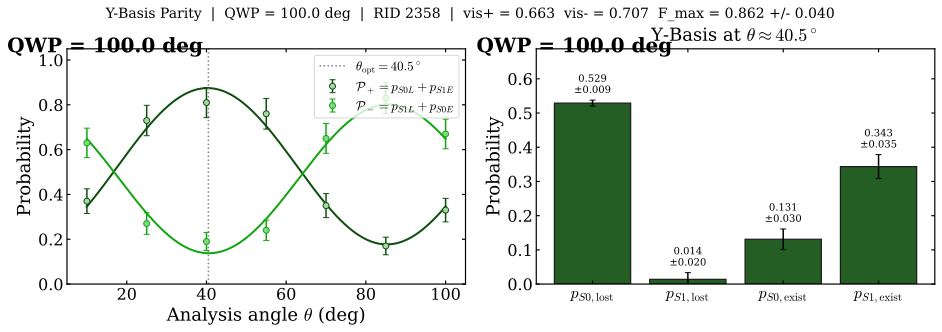

In [1522]:
# parity_plus  = p_S0_L + p_S1_E
# parity_minus = p_S1_L + p_S0_E
# Bar order: [p_S1_L, p_S0_L, p_S1_E, p_S0_E]
LBL_CATS = [
    r"$p_{S1,\mathrm{lost}}$",
    r"$p_{S0,\mathrm{lost}}$",
    r"$p_{S1,\mathrm{exist}}$",
    r"$p_{S0,\mathrm{exist}}$",
]
LBL_PARITY_A = r"$\mathcal{P}_+ = p_{S0L} + p_{S1E}$"
LBL_PARITY_B = r"$\mathcal{P}_- = p_{S1L} + p_{S0E}$"

analyzed_by_qwp = {}   # populated here; reused by Cell 6 and Cell 7

for qv in unique_qwp:
    slice_df = df[df["QWP"] == qv].copy()
    n_rows   = len(slice_df)
    n_hwp_in = len(slice_df["HWP"].unique())

    print(f"\n{'='*65}")
    print(f"QWP = {qv:.1f} deg  |  N = {n_rows} rows  |  HWP angles in slice: {n_hwp_in}")

    if n_hwp_in < 4:
        print(f"  SKIPPED: only {n_hwp_in} unique HWP angle(s) in this slice "
              f"(cos^4 fit requires >= 4). Run more HWP points to enable analysis.")
        continue

    result = safe_analyze_qwp_slice(slice_df, hist_thres=HIST_THRES)

    if result is None:
        print(f"  SKIPPED: safe_analyze_qwp_slice returned None "
              f"(< 4 valid single-click HWP angles after filtering).")
        continue

    angles   = result["angles"]
    res      = result["res"]
    fits     = result["fits"]

    vis_plus      = fits["parity_plus"]["vis"]
    vis_plus_err  = fits["parity_plus"]["vis_err"]
    vis_minus     = fits["parity_minus"]["vis"]
    vis_minus_err = fits["parity_minus"]["vis_err"]

    theta_opt, _, plus_dom = select_theta_opt(result, use_fits=True)
    F_max, sigma_F = qwp_max_fid_estimate(theta_opt, fits)

    print(f"  n_angles_valid = {len(angles)}  |  HWP range = "
          f"{angles.min():.1f} -- {angles.max():.1f} deg")
    print(f"  vis_plus       = {vis_plus:.4f} +/- {vis_plus_err:.4f}")
    print(f"  vis_minus      = {vis_minus:.4f} +/- {vis_minus_err:.4f}")
    print(f"  theta_opt      = {theta_opt:.2f} deg  (plus_dominant = {plus_dom})")
    print(f"  F_max (per-QWP estimator, registry.py) = {F_max:.4f} +/- {sigma_F:.4f}")

    analyzed_by_qwp[qv] = {
        "result":       result,
        "theta_opt":    theta_opt,
        "plus_dom":     plus_dom,
        "vis_plus":     vis_plus,
        "vis_plus_err": vis_plus_err,
        "vis_minus":    vis_minus,
        "vis_minus_err":vis_minus_err,
        "F_max":        F_max,
        "sigma_F":      sigma_F,
    }

    # --- Two-panel figure ---
    fig, (ax_l, ax_r) = plt.subplots(1, 2, figsize=(13, 4.5),
                                     constrained_layout=True)

    plot_parity_panel(
        ax_l, angles, result["theta_smooth"], res, fits,
        f"QWP = {qv:.1f} deg",
        COLORS_PARITY[basis],
        LBL_PARITY_A, LBL_PARITY_B,
    )
    ax_l.axvline(theta_opt, color="gray", ls=":", lw=1.5,
                 label=rf"$\theta_{{\rm opt}}={theta_opt:.1f}^\circ$")
    ax_l.legend(loc="upper right", fontsize=13)

    vals, errs = extract_quadratures_fit(theta_opt, fits)
    errs_clipped = [max(float(e), 0.0) for e in errs]
    plot_bar_panel(
        ax_r, vals, errs_clipped, theta_opt, basis,
        f"QWP = {qv:.1f} deg",
        COLORS_BAR[basis], LBL_CATS, biggest_outer=True,
    )

    fig.suptitle(
        f"{basis}-Basis Parity  |  QWP = {qv:.1f} deg  |  RID {run_rid}  |  "
        f"vis+ = {vis_plus:.3f}  vis- = {vis_minus:.3f}  "
        f"F_max = {F_max:.3f} +/- {sigma_F:.3f}",
        fontsize=14,
    )
    plt.show()

if not analyzed_by_qwp:
    print("\nNo QWP values produced valid fits. Collect more data (more HWP angles "
          "per QWP value) and re-run.")

## 6. Per-QWP Summary Table

Registry-style table (mirrors `archive/Analysis/registry.csv` columns):
qwp, n_angles, vis_plus, vis_minus, theta_opt, F_max, F_max_err, is_best_in_file.

F_max is the per-QWP max-fidelity estimate from `registry.qwp_max_fid_estimate`:
`0.5*(A+D+2*sqrt(A*D))` where A, D are the top-2 quadrature values at theta_opt.
This is the Z-basis contribution only; full Bell fidelity requires all 3 bases.

 QWP (deg)  n_hwp      vis+   vis+_e      vis-   vis-_e   theta_opt     F_max    F_err    best
-----------------------------------------------------------------------------------------------
      10.0      7    0.7237   0.0351    0.7682   0.0278       63.57    0.8720   0.0404  (best)
      20.0      7    0.6837   0.0542    0.6675   0.0519       25.15    0.8157   0.0720  
      30.0      7    0.6366   0.0378    0.6907   0.0299       77.82    0.8246   0.0604  
      40.0      7    0.5042   0.0527    0.5415   0.0516       85.03    0.7341   0.0514  
      50.0      7    0.5598   0.0736    0.5464   0.0547       50.94    0.8000   0.0391  
      60.0      7    0.5198   0.0489    0.5978   0.0652       15.23    0.8028   0.0375  
      70.0      7    0.6613   0.0440    0.6848   0.0394       22.44    0.8253   0.0642  
      80.0      7    0.7638   0.0620    0.7817   0.0586       30.56    0.8702   0.0470  
      90.0      7    0.7141   0.0663    0.8326   0.0490       34.89    0.8664   0.0550  
  

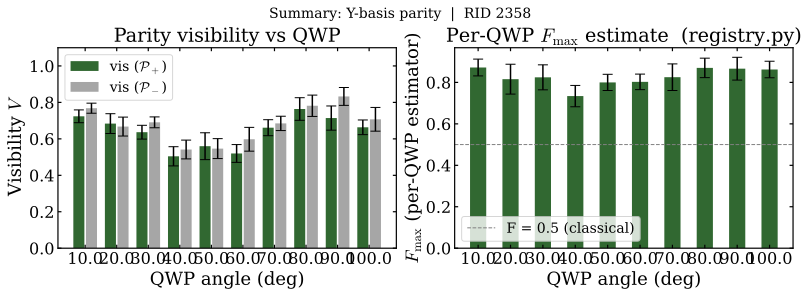

In [1523]:
if not analyzed_by_qwp:
    print("No QWP analysis results available.")
else:
    # Find best QWP by F_max
    best_qwp = max(analyzed_by_qwp, key=lambda q: analyzed_by_qwp[q]["F_max"])

    print(f"{'QWP (deg)':>10}  {'n_hwp':>5}  {'vis+':>8}  {'vis+_e':>7}  "
          f"{'vis-':>8}  {'vis-_e':>7}  {'theta_opt':>10}  "
          f"{'F_max':>8}  {'F_err':>7}  {'best':>6}")
    print("-" * 95)

    rows = []
    for qv in sorted(analyzed_by_qwp):
        r  = analyzed_by_qwp[qv]
        n  = len(r["result"]["angles"])
        best_flag = "(best)" if qv == best_qwp else ""
        print(
            f"{qv:10.1f}  {n:5d}  "
            f"{r['vis_plus']:8.4f}  {r['vis_plus_err']:7.4f}  "
            f"{r['vis_minus']:8.4f}  {r['vis_minus_err']:7.4f}  "
            f"{r['theta_opt']:10.2f}  "
            f"{r['F_max']:8.4f}  {r['sigma_F']:7.4f}  {best_flag}"
        )
        rows.append({
            "qwp":            qv,
            "n_hwp":          n,
            "vis_plus":       r["vis_plus"],
            "vis_plus_err":   r["vis_plus_err"],
            "vis_minus":      r["vis_minus"],
            "vis_minus_err":  r["vis_minus_err"],
            "theta_opt":      r["theta_opt"],
            "F_max":          r["F_max"],
            "F_max_err":      r["sigma_F"],
            "is_best_in_file": qv == best_qwp,
        })

    summary_df = pd.DataFrame(rows)
    print(f"\nBest QWP = {best_qwp:.1f} deg  "
          f"(F_max = {analyzed_by_qwp[best_qwp]['F_max']:.4f} +/- "
          f"{analyzed_by_qwp[best_qwp]['sigma_F']:.4f})")

    # Visibility bar chart
    if len(rows) > 0:
        fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4), constrained_layout=True)
        qvals = [r["qwp"] for r in rows]
        x = np.arange(len(qvals))
        ax1.bar(x - 0.2, [r["vis_plus"] for r in rows],
                width=0.35, yerr=np.clip([r["vis_plus_err"] for r in rows], 0, None),
                color=COLORS_BAR[basis], alpha=0.85, capsize=5, label=r"vis ($\mathcal{P}_+$)")
        ax1.bar(x + 0.2, [r["vis_minus"] for r in rows],
                width=0.35, yerr=np.clip([r["vis_minus_err"] for r in rows], 0, None),
                color="#888888", alpha=0.75, capsize=5, label=r"vis ($\mathcal{P}_-$)")
        ax1.set_xticks(x)
        ax1.set_xticklabels([f"{q:.1f}" for q in qvals])
        ax1.set_xlabel("QWP angle (deg)")
        ax1.set_ylabel(r"Visibility $V$")
        ax1.set_title("Parity visibility vs QWP")
        ax1.set_ylim(0, 1.1)
        ax1.legend()

        ax2.bar(x, [r["F_max"] for r in rows],
                width=0.5, yerr=np.clip([r["F_max_err"] for r in rows], 0, None),
                color=COLORS_BAR[basis], alpha=0.85, capsize=5)
        ax2.axhline(0.5, color="gray", ls="--", lw=1, label="F = 0.5 (classical)")
        ax2.set_xticks(x)
        ax2.set_xticklabels([f"{q:.1f}" for q in qvals])
        ax2.set_xlabel("QWP angle (deg)")
        ax2.set_ylabel(r"$F_{\rm max}$ (per-QWP estimator)")
        ax2.set_title(r"Per-QWP $F_{\rm max}$ estimate  (registry.py)")
        ax2.legend()

        plt.suptitle(f"Summary: {basis}-basis parity  |  RID {run_rid}", fontsize=14)
        plt.show()

## 7. Multi-Basis Bell Fidelity (optional, Z + X and/or Y)

A Z-only run produces the Z-basis parity oscillations and the per-QWP F_max
estimate above. The **full Bell-state fidelity** requires all three bases
(Z + X + Y) and cannot be computed from Z-basis data alone.

This cell provides the hook: set `FILE_X` / `QWP_X` and optionally `FILE_Y` /
`QWP_Y` (paths to the corresponding ZParityExperiment `.h5` files for those
bases) and `HIST_THRES_X` / `HIST_THRES_Y`. Then re-run to compute
`fidelity_two_basis` (Z+X, Blinov lower bound) or `fidelity_three_basis`
(Z+X+Y, equality), and render `create_figure` with the publication panels.

Reference: `archive/Analysis/Parity_ANALYSIS.ipynb` and `parity_lib.py`.

In [1524]:
########################################
# Set FILE_X / FILE_Y to the .h5 paths for those bases.
# Leave as None to skip.
FILE_X  = None   # e.g. r"...\repository\results\2026-xx-xx\HH\000000NNN-ZParityExperiment.h5"
QWP_X   = None   # QWP angle (deg) to use from that file
HIST_THRES_X = 19

FILE_Y  = None
QWP_Y   = None
HIST_THRES_Y = 19

# Best Z-basis QWP (from Cell 6 summary); override if needed
QWP_Z   = best_qwp if analyzed_by_qwp else None
########################################

if not analyzed_by_qwp:
    print("No Z-basis analysis available — run Cell 5 first.")
elif QWP_Z is None:
    print("QWP_Z is None — set it to the desired Z-basis QWP angle.")
else:
    print(f"Z-basis QWP = {QWP_Z:.1f} deg  (from Cell 6 best)")
    print(f"X-basis file: {FILE_X or 'NOT SET'}")
    print(f"Y-basis file: {FILE_Y or 'NOT SET'}")
    print()
    print("NOTE: With Z-basis data only, this notebook reports:")
    print("  - Per-QWP parity oscillations (Cell 5)")
    print("  - Per-QWP F_max estimator from registry.py (Cell 6)")
    print("To compute the full Bell-state fidelity, set FILE_X (and optionally FILE_Y)")
    print("above and re-run this cell.")

Z-basis QWP = 10.0 deg  (from Cell 6 best)
X-basis file: NOT SET
Y-basis file: NOT SET

NOTE: With Z-basis data only, this notebook reports:
  - Per-QWP parity oscillations (Cell 5)
  - Per-QWP F_max estimator from registry.py (Cell 6)
To compute the full Bell-state fidelity, set FILE_X (and optionally FILE_Y)
above and re-run this cell.


In [1525]:
# This cell runs only when at least FILE_X is set and the Z-basis has valid analysis.

if not analyzed_by_qwp or QWP_Z is None:
    print("Skipping: no Z-basis analysis.")
elif FILE_X is None:
    print("Skipping: FILE_X not set. Set FILE_X / QWP_X in the cell above to enable.")
else:
    # Build per_basis dict for parity_lib.create_figure
    per_basis = {}

    # Z basis (already analyzed)
    z_result   = analyzed_by_qwp[QWP_Z]["result"]
    z_theta, _, z_plus_dom = select_theta_opt(z_result, use_fits=True)
    z_vals, z_errs = extract_quadratures_fit(z_theta, z_result["fits"])
    z_big, z_small = select_big_small(z_plus_dom)
    per_basis["Z"] = dict(
        analyze=z_result, theta_opt=z_theta,
        vals=z_vals, errs=z_errs,
        big_idx=z_big, small_idx=z_small,
        plus_dominant=z_plus_dom,
        colors_parity=COLORS_PARITY["Z"],
        color_bar=COLORS_BAR["Z"],
        lbl_cats=LBL_CATS,
        lbl_parity_a=LBL_PARITY_A,
        lbl_parity_b=LBL_PARITY_B,
    )

    # X basis
    x_df, _x_at = load_h5_as_df(FILE_X)
    x_slice = x_df[x_df["QWP"] == QWP_X].copy()
    x_result = safe_analyze_qwp_slice(x_slice, hist_thres=HIST_THRES_X)
    if x_result is None:
        print(f"X-basis: safe_analyze_qwp_slice returned None for QWP={QWP_X}")
    else:
        x_theta, _, x_plus_dom = select_theta_opt(x_result, use_fits=True)
        x_vals, x_errs = extract_quadratures_fit(x_theta, x_result["fits"])
        x_big, x_small = select_big_small(x_plus_dom)
        print(f"X-basis QWP={QWP_X:.1f}: vis+={x_result['fits']['parity_plus']['vis']:.4f}  "
              f"theta_opt={x_theta:.2f}")
        per_basis["X"] = dict(
            analyze=x_result, theta_opt=x_theta,
            vals=x_vals, errs=x_errs,
            big_idx=x_big, small_idx=x_small,
            plus_dominant=x_plus_dom,
            colors_parity=COLORS_PARITY["X"],
            color_bar=COLORS_BAR["X"],
            lbl_cats=LBL_CATS,
            lbl_parity_a=LBL_PARITY_A,
            lbl_parity_b=LBL_PARITY_B,
        )

    # Y basis (optional)
    if FILE_Y is not None and QWP_Y is not None:
        y_df, _y_at = load_h5_as_df(FILE_Y)
        y_slice = y_df[y_df["QWP"] == QWP_Y].copy()
        y_result = safe_analyze_qwp_slice(y_slice, hist_thres=HIST_THRES_Y)
        if y_result is None:
            print(f"Y-basis: safe_analyze_qwp_slice returned None for QWP={QWP_Y}")
        else:
            y_theta, _, y_plus_dom = select_theta_opt(y_result, use_fits=True)
            y_vals, y_errs = extract_quadratures_fit(y_theta, y_result["fits"])
            y_big, y_small = select_big_small(y_plus_dom)
            print(f"Y-basis QWP={QWP_Y:.1f}: vis+={y_result['fits']['parity_plus']['vis']:.4f}  "
                  f"theta_opt={y_theta:.2f}")
            per_basis["Y"] = dict(
                analyze=y_result, theta_opt=y_theta,
                vals=y_vals, errs=y_errs,
                big_idx=y_big, small_idx=y_small,
                plus_dominant=y_plus_dom,
                colors_parity=COLORS_PARITY["Y"],
                color_bar=COLORS_BAR["Y"],
                lbl_cats=LBL_CATS,
                lbl_parity_a=LBL_PARITY_A,
                lbl_parity_b=LBL_PARITY_B,
            )

    # Compute fidelity
    if "Z" in per_basis and "X" in per_basis:
        if "Y" in per_basis:
            F, sF = fidelity_three_basis(per_basis)
            fid_mode = "equal"
            print(f"\nThree-basis fidelity (Z+X+Y): F = {F:.4f} +/- {sF:.4f}")
            print("Correlator contributions:")
            for k, (c, s) in correlator_per_basis(per_basis).items():
                print(f"  {k}: {c:+.4f} +/- {s:.4f}")
        else:
            F, sF = fidelity_two_basis(
                per_basis["Z"]["vals"], per_basis["Z"]["errs"],
                per_basis["X"]["vals"], per_basis["X"]["errs"],
                big_idx_z=per_basis["Z"]["big_idx"],
                small_idx_z=per_basis["Z"]["small_idx"],
                big_idx_x=per_basis["X"]["big_idx"],
                small_idx_x=per_basis["X"]["small_idx"],
            )
            fid_mode = "lower"
            print(f"\nTwo-basis fidelity (Z+X, Blinov lower bound): F >= {F:.4f} +/- {sF:.4f}")

        basis_order = tuple(b for b in ("Z", "X", "Y") if b in per_basis)
        create_figure(
            per_basis, basis_order=basis_order,
            fid=F, fid_err=sF, fid_mode=fid_mode,
            use_fits=True, filename=f"parity_figure_RID{run_rid}.svg",
            show_title=True,
        )
    else:
        print("Need at least Z + X basis data to compute fidelity. Set FILE_X above.")

Skipping: FILE_X not set. Set FILE_X / QWP_X in the cell above to enable.


## 8. Dataset Browser

All datasets and archive entries with shapes and value ranges.

In [1526]:
print(f"File: {os.path.basename(filepath)}")
print(f"RID:  {run_rid}")
print()

with h5py.File(filepath, "r", locking=False) as hf:
    print("=== datasets/ ===")
    if "datasets" in hf:
        for k in sorted(hf["datasets"].keys()):
            ds = hf[f"datasets/{k}"]
            data_arr = ds[()]
            if hasattr(data_arr, '__len__') and len(data_arr) > 0:
                vmin = float(np.min(data_arr))
                vmax = float(np.max(data_arr))
                print(f"  {k:40s}  {str(ds.dtype):8s}  shape={str(data_arr.shape):16s} "
                      f" [{vmin:.4g} .. {vmax:.4g}]")
            elif hasattr(data_arr, '__len__'):
                print(f"  {k:40s}  {str(ds.dtype):8s}  shape={str(data_arr.shape):16s}  (empty)")
            else:
                val = data_arr.decode() if isinstance(data_arr, bytes) else data_arr
                print(f"  {k:40s}  = {val}")

    print()
    print("=== archive/ ===")
    if "archive" in hf:
        for k in sorted(hf["archive"].keys()):
            v = hf[f"archive/{k}"][()]
            if isinstance(v, np.ndarray) and v.ndim == 0:
                val = float(v)
            elif isinstance(v, bytes):
                val = v.decode()
            else:
                val = v
            print(f"  {k:40s}  = {val}")

    print()
    print("=== top-level groups ===")
    for k in hf.keys():
        print(f"  {k}")

File: 000002358-ParityExperiment.h5
RID:  2358

=== datasets/ ===
  HWP_angles                                float64   shape=(7000,)           [10 .. 100]
  QWP_angles                                float64   shape=(7000,)           [10 .. 100]
  SPCM1_timestamps                          float64   shape=(7000,)           [0 .. 5.766e-06]
  SPCM2_timestamps                          float64   shape=(7000,)           [0 .. 5.764e-06]
  counts_background                         int32     shape=(7000,)           [0 .. 12]
  counts_signal                             int32     shape=(7000,)           [0 .. 60]
  f_RF_2ph                                  = 613660.0000000141
  f_mw_2ph                                  = 249378000.0
  how_many_atoms                            int32     shape=(7000,)           [1 .. 21]
  measurement_progress                      = 100
  trials_per_meas                           int32     shape=(7000,)           [1 .. 1259]

=== archive/ ===
  HWP_angle_max     